# Lab 1 - Simple ML Pipeline with Scikit-Learn



## Introduction

In this notebook, we'll walk through a basic machine learning pipeline. We will:
1. Load and understand the dataset.
2. Preprocess the data.
3. Split the data into training and test sets.
4. Train a machine learning model.
5. Evaluate the model's performance.

Resources:
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression
- https://pandas.pydata.org/docs/

In [1]:
# Импортируем нужные библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Step 1: Load the Dataset

In [2]:
# Load the breast cancer dataset
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

# Display the first few rows of the dataset
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### Изучаем датасет
Отвечаем на 4 вопроса из TODO, каждый вопрос в отдельной ячейке.

In [3]:
# 1. Сколько признаков (колонок) и как они называются?
print("Количество строк:", df.shape[0])
print("Количество колонок (вместе с target):", df.shape[1])
print("Количество признаков:", len(data.feature_names))
print()
print("Названия признаков:")
for name in data.feature_names:
    print(name)

Количество строк: 569
Количество колонок (вместе с target): 31
Количество признаков: 30

Названия признаков:
mean radius
mean texture
mean perimeter
mean area
mean smoothness
mean compactness
mean concavity
mean concave points
mean symmetry
mean fractal dimension
radius error
texture error
perimeter error
area error
smoothness error
compactness error
concavity error
concave points error
symmetry error
fractal dimension error
worst radius
worst texture
worst perimeter
worst area
worst smoothness
worst compactness
worst concavity
worst concave points
worst symmetry
worst fractal dimension


In [4]:
# 2. Типы данных колонок
print(df.dtypes)

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

In [5]:
# 3. Есть ли пропущенные значения?
print(df.isnull().sum())
print()
print("Всего пропусков:", df.isnull().sum().sum())

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Всего пропусков: 0


In [6]:
# 4. Какие уникальные значения в колонке target?
print(df['target'].unique())
print()
# сколько объектов каждого класса
print(df['target'].value_counts())
print()
# 0 - malignant (злокачественная), 1 - benign (доброкачественная)
print(data.target_names)

[0 1]

target
1    357
0    212
Name: count, dtype: int64

['malignant' 'benign']


## Step 2: Data Preprocessing

In [7]:
# Separate features and target variable
X = df.drop(columns='target')
y = df['target']

In [8]:
# Standardize the features to similar ranges
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [9]:
# Выводим первую строку X и X_scaled, чтобы сравнить значения
print("Первая строка X (до масштабирования):")
print(X.iloc[0])
print()
print("Первая строка X_scaled (после масштабирования):")
print(X_scaled[0])

Первая строка X (до масштабирования):
mean radius                  17.990000
mean texture                 10.380000
mean perimeter              122.800000
mean area                  1001.000000
mean smoothness               0.118400
mean compactness              0.277600
mean concavity                0.300100
mean concave points           0.147100
mean symmetry                 0.241900
mean fractal dimension        0.078710
radius error                  1.095000
texture error                 0.905300
perimeter error               8.589000
area error                  153.400000
smoothness error              0.006399
compactness error             0.049040
concavity error               0.053730
concave points error          0.015870
symmetry error                0.030030
fractal dimension error       0.006193
worst radius                 25.380000
worst texture                17.330000
worst perimeter             184.600000
worst area                 2019.000000
worst smoothness          

**Сравнение:** до масштабирования признаки сильно отличаются по величине (например, `mean area` около 1001, а `mean smoothness` около 0.1). После `StandardScaler` все значения стали маленькими (среднее 0, стандартное отклонение 1), поэтому признаки находятся в одном масштабе.

In [10]:
# Проверим, что масштабирование сработало: среднее ~ 0, std ~ 1
print("Среднее первых 3 признаков:", X_scaled.mean(axis=0)[:3].round(3))
print("Std первых 3 признаков:", X_scaled.std(axis=0)[:3].round(3))

Среднее первых 3 признаков: [-0.  0. -0.]
Std первых 3 признаков: [1. 1. 1.]


## Step 3: Split the Data into Training and Testing Sets

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

## Step 4: Train a Model

In [12]:
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

## Step 5: Make Predictions and Evaluate the Model

In [13]:
# Make predictions on the test data
y_pred = model.predict(X_test)

In [14]:
# Посмотрим первые 10 предсказаний и сравним с настоящими ответами
print("Настоящие:   ", y_test[:10].tolist())
print("Предсказано: ", y_pred[:10].tolist())

Настоящие:    [1, 0, 0, 1, 1, 0, 0, 0, 1, 1]
Предсказано:  [1, 0, 0, 1, 1, 0, 0, 0, 1, 1]


In [15]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.98


In [16]:
# Матрица ошибок (confusion matrix)
# строки - настоящие классы, столбцы - предсказанные
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[ 62   1]
 [  2 106]]


In [17]:
# Подробный отчёт по метрикам
print(classification_report(y_test, y_pred, target_names=data.target_names))

              precision    recall  f1-score   support

   malignant       0.97      0.98      0.98        63
      benign       0.99      0.98      0.99       108

    accuracy                           0.98       171
   macro avg       0.98      0.98      0.98       171
weighted avg       0.98      0.98      0.98       171



## Exercise 1: Experiment with Different Models

Objective: To understand how different models perform on the same dataset and to practice replacing models in a pipeline.

Instructions:

- Replace the `Logistic Regression` model with another classifier, such as `KNeighborsClassifier` or `DecisionTreeClassifier`.
- Train and evaluate the new model on the same training and test sets.
- Compare the accuracy with those from the `Logistic Regression` model.

Questions:

- How did the performance of the new model compare to Logistic Regression?

In [18]:
# Создаём три модели
log_model = LogisticRegression()
knn_model = KNeighborsClassifier(n_neighbors=5)
tree_model = DecisionTreeClassifier(random_state=42)

In [19]:
# Обучаем модели на тех же train данных
log_model.fit(X_train, y_train)
knn_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [20]:
# Делаем предсказания на тестовых данных
log_pred = log_model.predict(X_test)
knn_pred = knn_model.predict(X_test)
tree_pred = tree_model.predict(X_test)

In [21]:
# Считаем accuracy каждой модели
log_acc = accuracy_score(y_test, log_pred)
knn_acc = accuracy_score(y_test, knn_pred)
tree_acc = accuracy_score(y_test, tree_pred)

print("Logistic Regression:", round(log_acc, 4))
print("KNN:                ", round(knn_acc, 4))
print("Decision Tree:      ", round(tree_acc, 4))

Logistic Regression: 0.9825
KNN:                 0.9591
Decision Tree:       0.9415


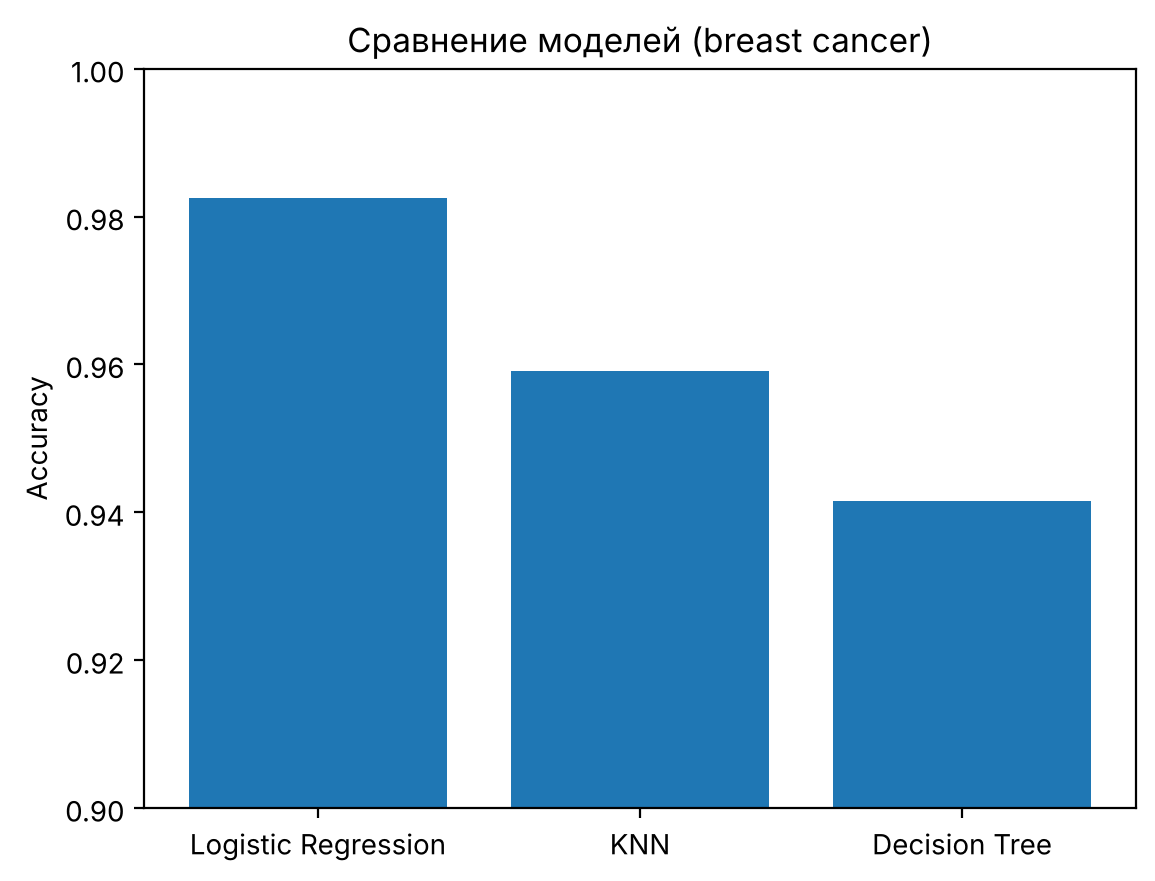

In [22]:
# Столбчатая диаграмма для сравнения
names = ["Logistic Regression", "KNN", "Decision Tree"]
accs = [log_acc, knn_acc, tree_acc]

plt.bar(names, accs)
plt.ylim(0.9, 1.0)   # ограничиваем ось, чтобы разница была видна
plt.ylabel("Accuracy")
plt.title("Сравнение моделей (breast cancer)")
plt.show()

In [23]:
# Сколько ошибок сделала каждая модель
print("Ошибок у Logistic Regression:", (log_pred != y_test).sum())
print("Ошибок у KNN:", (knn_pred != y_test).sum())
print("Ошибок у Decision Tree:", (tree_pred != y_test).sum())

Ошибок у Logistic Regression: 3
Ошибок у KNN: 7
Ошибок у Decision Tree: 10


**Ответ:** Logistic Regression показала лучший результат.

| Модель | Accuracy | Ошибок (из 171) |
|---|---|---|
| Logistic Regression | 0.9825 | 3 |
| KNN (k=5) | 0.9591 | 7 |
| Decision Tree | 0.9415 | 10 |

- KNN хуже примерно на 2 процента, а Decision Tree примерно на 4 процента.
- Вероятная причина: после масштабирования классы почти разделяются прямой линией, и это подходит логистической регрессии. Дерево без ограничений склонно переобучаться.
- Все модели дали больше 94 процентов, поэтому разница небольшая. В тесте всего 171 объект, и одна ошибка меняет accuracy примерно на 0.6 процента.

# Exercise 2: Experiment with different datasets

Choose 1 or these datasets and compare the accuracies.

- Wine Dataset

```python
from sklearn.datasets import load_wine
data = load_wine()
```
- Diabetes Dataset
```python
from sklearn.datasets import load_diabetes
data = load_diabetes()
```

Выбираем **Wine dataset**, потому что это задача классификации, как и в лабе. Diabetes это задача регрессии (цель непрерывная), для неё accuracy не подходит.

In [24]:
from sklearn.datasets import load_wine

wine = load_wine()
df_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
df_wine['target'] = wine.target
df_wine.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [25]:
# Смотрим на данные
print("Размер:", df_wine.shape)
print("Пропусков:", df_wine.isnull().sum().sum())
print()
print(df_wine['target'].value_counts())

Размер: (178, 14)
Пропусков: 0

target
1    71
0    59
2    48
Name: count, dtype: int64


In [26]:
# Делим на признаки и целевую переменную
X_w = df_wine.drop(columns='target')
y_w = df_wine['target']

In [27]:
# Сначала делим на train и test, потом масштабируем
# (scaler учим только на train, чтобы не было утечки данных)
X_w_train, X_w_test, y_w_train, y_w_test = train_test_split(
    X_w, y_w, test_size=0.3, random_state=42, stratify=y_w)

scaler_w = StandardScaler()
X_w_train = scaler_w.fit_transform(X_w_train)
X_w_test = scaler_w.transform(X_w_test)

In [28]:
# Обучаем те же три модели на вине
log_w = LogisticRegression(max_iter=1000)
knn_w = KNeighborsClassifier(n_neighbors=5)
tree_w = DecisionTreeClassifier(random_state=42)

log_w.fit(X_w_train, y_w_train)
knn_w.fit(X_w_train, y_w_train)
tree_w.fit(X_w_train, y_w_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [29]:
# Считаем accuracy
log_w_acc = accuracy_score(y_w_test, log_w.predict(X_w_test))
knn_w_acc = accuracy_score(y_w_test, knn_w.predict(X_w_test))
tree_w_acc = accuracy_score(y_w_test, tree_w.predict(X_w_test))

print("Logistic Regression:", round(log_w_acc, 4))
print("KNN:                ", round(knn_w_acc, 4))
print("Decision Tree:      ", round(tree_w_acc, 4))

Logistic Regression: 0.9815
KNN:                 0.9444
Decision Tree:       0.963


In [30]:
# Сравниваем обе датасета в таблице
compare = pd.DataFrame({
    "Breast cancer": [log_acc, knn_acc, tree_acc],
    "Wine": [log_w_acc, knn_w_acc, tree_w_acc]
}, index=["Logistic Regression", "KNN", "Decision Tree"])

compare.round(4)

,Breast cancer,Wine
Logistic Regression,0.9825,0.9815
KNN,0.9591,0.9444
Decision Tree,0.9415,0.9630


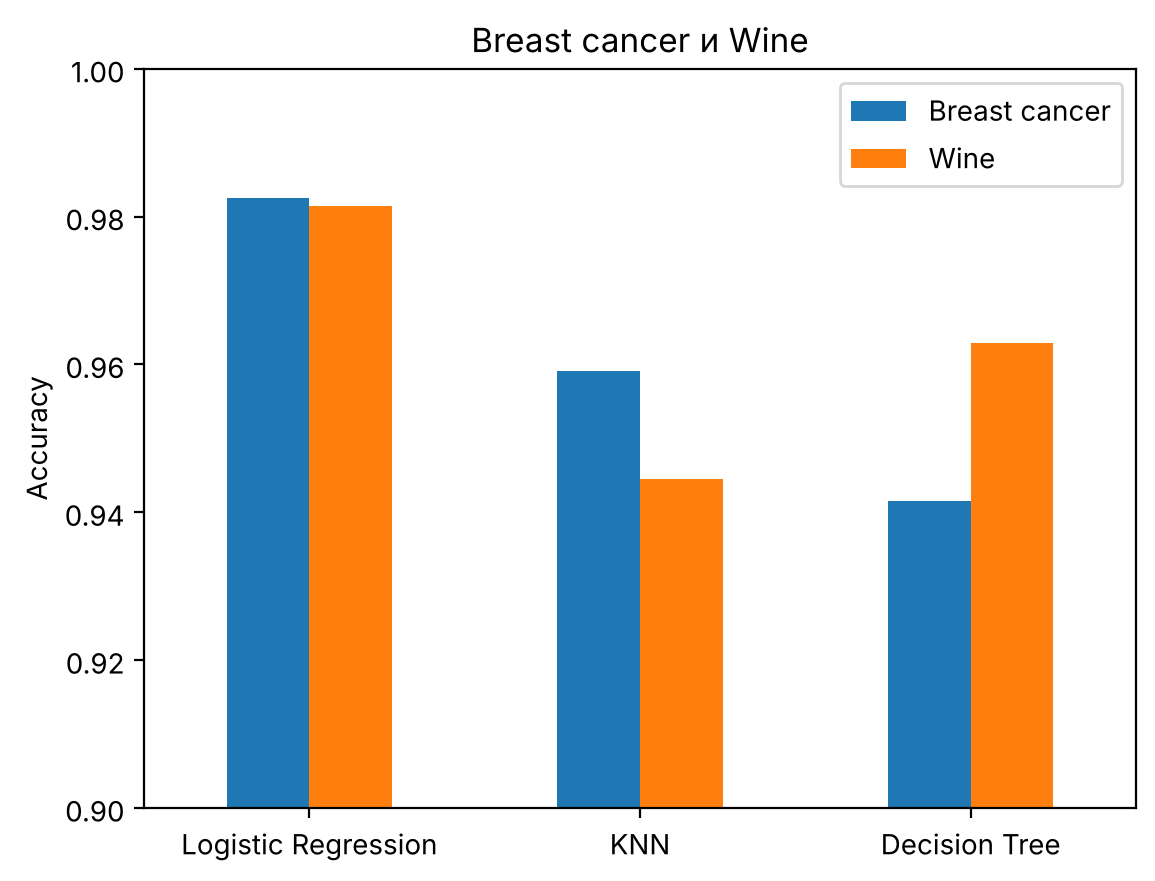

In [31]:
# График сравнения
compare.plot(kind="bar")
plt.ylim(0.9, 1.0)
plt.ylabel("Accuracy")
plt.title("Breast cancer и Wine")
plt.xticks(rotation=0)
plt.show()

In [32]:
# Подробный отчёт для лучшей модели на вине (Logistic Regression)
y_w_pred = log_w.predict(X_w_test)
print(classification_report(y_w_test, y_w_pred, target_names=wine.target_names))
print(confusion_matrix(y_w_test, y_w_pred))

              precision    recall  f1-score   support

     class_0       0.95      1.00      0.97        18
     class_1       1.00      0.95      0.98        21
     class_2       1.00      1.00      1.00        15

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54

[[18  0  0]
 [ 1 20  0]
 [ 0  0 15]]
